In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [12]:
# Reload the latest survey records
df = pd.read_csv("data/healthcare_survey.csv")

# Recreate the cleaned dataset
df_clean = df.copy()

# Convert date column
df_clean["created_at"] = pd.to_datetime(
    df_clean["created_at"],
    errors="coerce"
)

# Display dataset size
print("Total survey records:", len(df_clean))
print("Total variables:", len(df_clean.columns))

df_clean.head()

Total survey records: 9
Total variables: 9


,age,gender,total_income,utilities,entertainment,school_fees,shopping,healthcare,created_at
0,23,Male,2999.62,45.0,67.0,0.0,0.0,0.0,2026-11-24 17:06:37.061
1,30,Female,54.00,56.0,76.0,32.0,0.0,0.0,2026-11-24 17:56:44.584
2,54,Male,78.00,78.0,0.0,0.0,0.0,0.0,2026-11-24 17:57:02.296
3,23,Female,800.00,0.0,0.0,0.0,34.0,21.0,2026-11-24 17:57:22.812
4,51,Male,700.00,0.0,0.0,544.0,311.0,0.0,2026-11-24 17:57:47.696


In [13]:
expense_columns = [
    "utilities",
    "entertainment",
    "school_fees",
    "shopping",
    "healthcare"
]

df_clean["total_expenses"] = df_clean[expense_columns].sum(axis=1)

df_clean["remaining_income"] = (
    df_clean["total_income"] - df_clean["total_expenses"]
)

df_clean.head()

,age,gender,total_income,utilities,entertainment,school_fees,shopping,healthcare,created_at,total_expenses,remaining_income
0,23,Male,2999.62,45.0,67.0,0.0,0.0,0.0,2026-11-24 17:06:37.061,112.0,2887.62
1,30,Female,54.00,56.0,76.0,32.0,0.0,0.0,2026-11-24 17:56:44.584,164.0,-110.00
2,54,Male,78.00,78.0,0.0,0.0,0.0,0.0,2026-11-24 17:57:02.296,78.0,0.00
3,23,Female,800.00,0.0,0.0,0.0,34.0,21.0,2026-11-24 17:57:22.812,55.0,745.00
4,51,Male,700.00,0.0,0.0,544.0,311.0,0.0,2026-11-24 17:57:47.696,855.0,-155.00


In [14]:
expense_columns = [
    "utilities",
    "entertainment",
    "school_fees",
    "shopping",
    "healthcare"
]

df_clean["total_expenses"] = df_clean[expense_columns].sum(axis=1)

df_clean["remaining_income"] = (
    df_clean["total_income"] - df_clean["total_expenses"]
)

df_clean.head()

,age,gender,total_income,utilities,entertainment,school_fees,shopping,healthcare,created_at,total_expenses,remaining_income
0,23,Male,2999.62,45.0,67.0,0.0,0.0,0.0,2026-11-24 17:06:37.061,112.0,2887.62
1,30,Female,54.00,56.0,76.0,32.0,0.0,0.0,2026-11-24 17:56:44.584,164.0,-110.00
2,54,Male,78.00,78.0,0.0,0.0,0.0,0.0,2026-11-24 17:57:02.296,78.0,0.00
3,23,Female,800.00,0.0,0.0,0.0,34.0,21.0,2026-11-24 17:57:22.812,55.0,745.00
4,51,Male,700.00,0.0,0.0,544.0,311.0,0.0,2026-11-24 17:57:47.696,855.0,-155.00


In [15]:
df_clean.describe()

,age,total_income,utilities,entertainment,school_fees,shopping,healthcare,created_at,total_expenses,remaining_income
count,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9,9.000000,9.000000
mean,41.555556,1514.624444,186.551111,93.666667,119.555556,149.444444,143.000000,2026-11-24 17:52:31.027111,692.217778,822.406667
min,23.000000,54.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2026-11-24 17:06:37.061000,55.000000,-1600.000000
25%,30.000000,300.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2026-11-24 17:57:02.296000,112.000000,-400.000000
50%,40.000000,800.000000,45.000000,0.000000,0.000000,0.000000,0.000000,2026-11-24 17:57:47.696000,500.000000,-110.000000
75%,51.000000,900.000000,78.000000,67.000000,200.000000,200.000000,21.000000,2026-11-24 17:59:03.787000,855.000000,745.000000
max,70.000000,7000.000000,800.000000,700.000000,544.000000,800.000000,700.000000,2026-11-24 18:00:04.773000,2500.000000,6500.000000
std,15.898987,2236.904537,321.709719,229.484204,193.105613,268.531707,279.900875,NaN,795.278226,2450.240893


In [16]:
income_by_age = (
    df_clean.groupby("age")["total_income"]
    .mean()
    .sort_values(ascending=False)
)

print("Average income by age:")
display(income_by_age)

Average income by age:


age
33    7000.00
23    1899.81
70     900.00
40     800.00
51     700.00
50     300.00
54      78.00
30      54.00
Name: total_income, dtype: float64

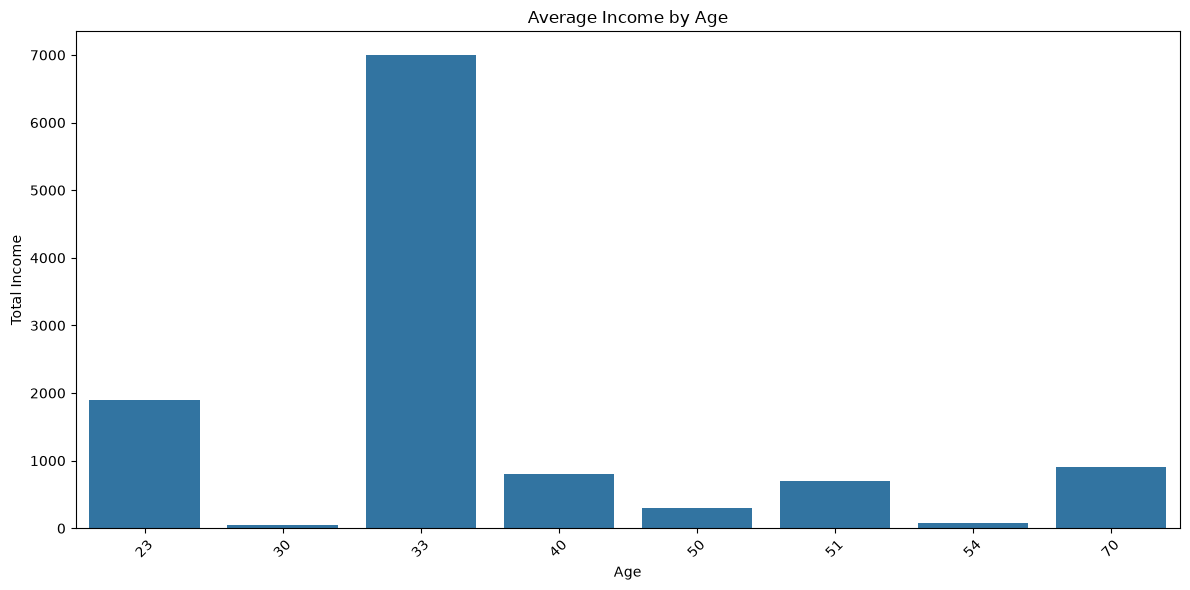

In [19]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_clean,
    x="age",
    y="total_income",
    errorbar=None
)

plt.title("Average Income by Age")
plt.xlabel("Age")
plt.ylabel("Total Income")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("exports/income_by_age.png", dpi=300)
plt.show()


In [20]:
# Calculate average spending by gender
gender_spending = df_clean.groupby("gender")[expense_columns].mean()

# Display the results
display(gender_spending)

,utilities,entertainment,school_fees,shopping,healthcare
gender,,,,,
Female,214.00,194.00,58.0,208.50,180.25
Male,30.75,16.75,211.0,127.75,0.00
Prefer not to say,699.96,0.00,0.0,0.00,566.00


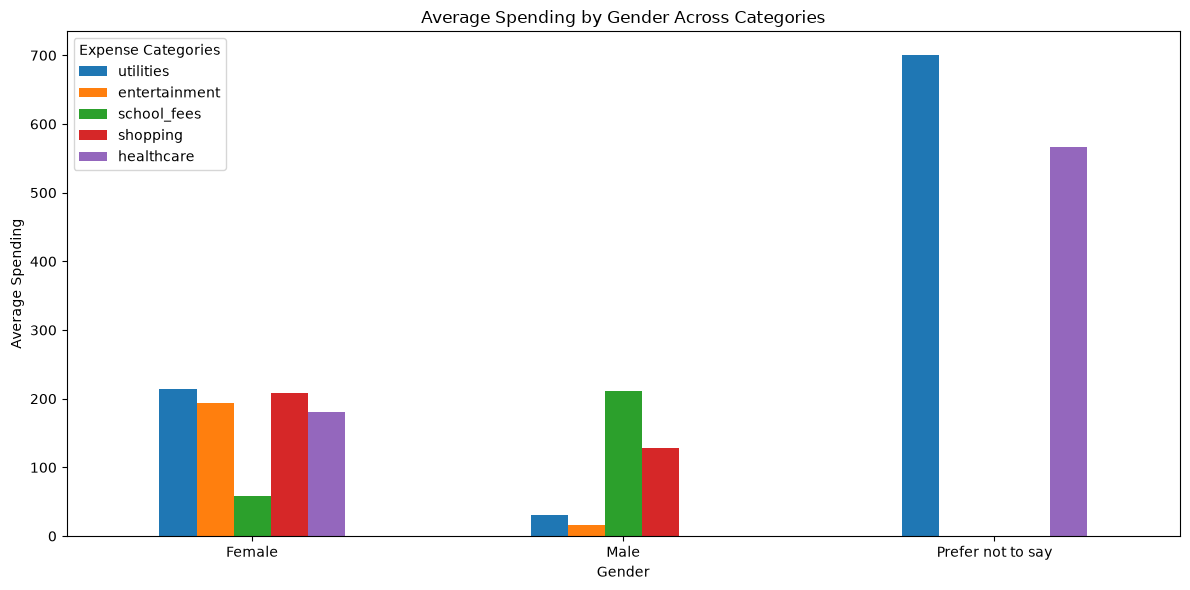

In [21]:
gender_spending.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Spending by Gender Across Categories")
plt.xlabel("Gender")
plt.ylabel("Average Spending")
plt.xticks(rotation=0)
plt.legend(title="Expense Categories")
plt.tight_layout()

plt.savefig("exports/gender_spending.png", dpi=300)
plt.show()

In [22]:
from pathlib import Path

for file in Path("exports").glob("*.png"):
    print(file.name)

gender_spending.png
income_by_age.png


In [23]:
# Summary statistics by gender
gender_summary = df_clean.groupby("gender").agg(
    participant_count=("gender", "count"),
    average_age=("age", "mean"),
    average_income=("total_income", "mean"),
    average_expenses=("total_expenses", "mean"),
    average_remaining_income=("remaining_income", "mean")
).round(2)

display(gender_summary)

,participant_count,average_age,average_income,average_expenses,average_remaining_income
gender,,,,,
Female,4,43.25,513.5,854.75,-341.25
Male,4,40.25,2694.4,386.25,2308.15
Prefer not to say,1,40.00,800.0,1265.96,-465.96


In [24]:
financial_summary = pd.DataFrame({
    "Metric": [
        "Average Income",
        "Average Expenses",
        "Average Remaining Income",
        "Highest Income",
        "Lowest Income"
    ],
    "Value": [
        df_clean["total_income"].mean(),
        df_clean["total_expenses"].mean(),
        df_clean["remaining_income"].mean(),
        df_clean["total_income"].max(),
        df_clean["total_income"].min()
    ]
})

display(financial_summary.round(2))

,Metric,Value
0,Average Income,1514.62
1,Average Expenses,692.22
2,Average Remaining Income,822.41
3,Highest Income,7000.00
4,Lowest Income,54.00


In [25]:
gender_summary.to_csv(
    "exports/gender_summary.csv"
)

financial_summary.to_csv(
    "exports/financial_summary.csv",
    index=False
)

print("Analysis summaries exported successfully!")

Analysis summaries exported successfully!


In [26]:
from pathlib import Path

print("PROJECT EXPORTS")
print("-" * 40)

for file in sorted(Path("exports").iterdir()):
    if file.is_file():
        print(f"{file.name} - {file.stat().st_size:,} bytes")

PROJECT EXPORTS
----------------------------------------
financial_summary.csv - 172 bytes
gender_spending.png - 112,189 bytes
gender_summary.csv - 216 bytes
income_by_age.png - 77,188 bytes
